# SVM — Thyroid Classification

Support vector machine with an RBF kernel. Two things it needs that the tree models did not:

- **Scaling**, because the kernel measures distance between patients and TSH runs to 530 while
  T4U sits near 1.
- **No missing values**, because `NaN` has no distance. Median imputation fills the gaps.

Both go inside a pipeline so they are fitted on the training folds only.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve)

CSV = "../dataset/hypothyroid.csv"
FEATURES = ["age", "sex", "TSH", "TT4", "T4U", "FTI"]
TARGET = "binaryClass"
CLASS_NAMES = ["negative", "hypothyroid"]
RANDOM_STATE = 42

## Load and clean

In [2]:
# Same cleaning as thyroid.ipynb section 3.
df = pd.read_csv(CSV, na_values="?")[FEATURES + [TARGET]]

known = df["sex"].notna()
df.loc[known, "sex"] = LabelEncoder().fit_transform(df.loc[known, "sex"])
df["sex"] = df["sex"].astype(float)

# LabelEncoder puts "N" first, and "N" is the hypothyroid group, so flip it.
df[TARGET] = 1 - LabelEncoder().fit_transform(df[TARGET])

clean = df[~(df["age"] > 120)].drop_duplicates()
X = clean[FEATURES]
y = clean[TARGET]
print(f"{len(clean)} patients, {y.sum()} hypothyroid ({100 * y.mean():.2f}%)")
clean.head()

3658 patients, 291 hypothyroid (7.96%)


,age,sex,TSH,TT4,T4U,FTI,binaryClass
0,41.0,0.0,1.30,125.0,1.14,109.0,0
1,23.0,0.0,4.10,102.0,NaN,NaN,0
2,46.0,1.0,0.98,109.0,0.91,120.0,0
3,70.0,0.0,0.16,175.0,NaN,NaN,0
4,70.0,0.0,0.72,61.0,0.87,70.0,0


## The pipeline

`SVC` has no `predict_proba` of its own, so `CalibratedClassifierCV` supplies one.

In [3]:
def svm(**kwargs):
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        CalibratedClassifierCV(
            SVC(class_weight="balanced", random_state=RANDOM_STATE, **kwargs), ensemble=False
        ),
    )


def evaluate(X_in, model, label):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_in, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    pred = (p >= 0.5).astype(int)
    return {
        "model": label,
        "avg_precision": round(average_precision_score(y_te, p), 4),
        "recall": round(((pred == 1) & (y_te == 1)).sum() / (y_te == 1).sum(), 4),
        "missed": int(((pred == 0) & (y_te == 1)).sum()),
        "false_alarms": int(((pred == 1) & (y_te == 0)).sum()),
    }

## 1. The log transform

TSH is heavily skewed. The same model is run twice, with one column transformed.

In [4]:
X_log = X.copy()
X_log["TSH"] = np.log1p(X_log["TSH"])

pd.DataFrame([
    evaluate(X, svm(), "RBF, raw TSH"),
    evaluate(X_log, svm(), "RBF, log1p(TSH)"),
]).set_index("model")

,avg_precision,recall,missed,false_alarms
model,,,,
"RBF, raw TSH",0.8846,0.7069,17,4
"RBF, log1p(TSH)",0.8846,0.7931,12,6


On the raw scale the kernel sees a patient with TSH 300 as far from one with TSH 30, when both
are plainly hypothyroid. The transform makes them neighbours. Everything below uses
`log1p(TSH)`.

## 2. Kernel and C

In [5]:
pd.DataFrame([
    evaluate(X_log, svm(kernel="linear"), "linear kernel"),
    evaluate(X_log, svm(), "RBF, C=1 (default)"),
    evaluate(X_log, svm(C=10), "RBF, C=10"),
    evaluate(X_log, svm(C=100), "RBF, C=100"),
]).set_index("model")

,avg_precision,recall,missed,false_alarms
model,,,,
linear kernel,0.9275,0.6207,22,4
"RBF, C=1 (default)",0.8846,0.7931,12,6
"RBF, C=10",0.8662,0.8276,10,8
"RBF, C=100",0.8429,0.8276,10,9


## 3. Grid search

Tuned on the training folds only, scored by average precision.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_log, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

grid = GridSearchCV(
    svm(),
    {"calibratedclassifiercv__estimator__C": [1, 10, 100, 1000],
     "calibratedclassifiercv__estimator__gamma": ["scale", 0.01, 0.1, 1]},
    scoring="average_precision",
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
)
grid.fit(X_train, y_train)
print(f"best params: {grid.best_params_}")
print(f"best CV average precision: {grid.best_score_:.4f}")

best params: {'calibratedclassifiercv__estimator__C': 1, 'calibratedclassifiercv__estimator__gamma': 0.01}
best CV average precision: 0.8487


## 4. Final model

In [7]:
proba = grid.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"test average precision: {average_precision_score(y_test, proba):.4f}\n")
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))
print("confusion matrix [rows = actual]")
print(confusion_matrix(y_test, pred))

test average precision: 0.9307

              precision    recall  f1-score   support

    negative     0.9724    0.9941    0.9831       674
 hypothyroid     0.9070    0.6724    0.7723        58

    accuracy                         0.9686       732
   macro avg     0.9397    0.8332    0.8777       732
weighted avg     0.9672    0.9686    0.9664       732

confusion matrix [rows = actual]
[[670   4]
 [ 19  39]]


The bottom-left cell is the one that matters for a screening test. Lowering the threshold
recovers missed patients at the cost of false alarms.

In [8]:
pd.DataFrame([
    {"threshold": t,
     "recall": round(((proba >= t) & (y_test == 1)).sum() / (y_test == 1).sum(), 4),
     "missed": int(((proba < t) & (y_test == 1)).sum()),
     "false_alarms": int(((proba >= t) & (y_test == 0)).sum())}
    for t in [0.05, 0.10, 0.20, 0.30, 0.50]
]).set_index("threshold")

,recall,missed,false_alarms
threshold,,,
0.05,1.0000,0,59
0.10,1.0000,0,33
0.20,0.8966,6,9
0.30,0.8103,11,6
0.50,0.6724,19,4


## 5. Precision-recall curve

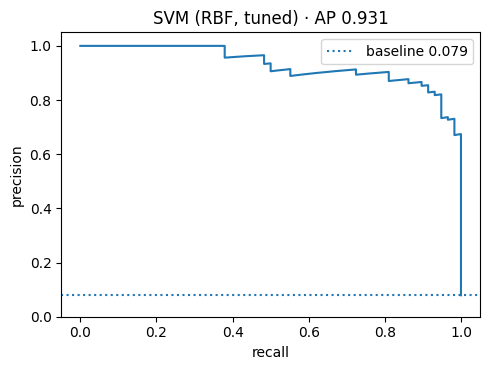

In [9]:
prec, rec, _ = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.plot(rec, prec)
ax.axhline(y_test.mean(), linestyle=":", label=f"baseline {y_test.mean():.3f}")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title(f"SVM (RBF, tuned) · AP {average_precision_score(y_test, proba):.3f}")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

## 6. What the kernel is doing

The full model works in six dimensions, which cannot be drawn. Refitting on the two features
that carry the most signal shows the shape of an RBF boundary.

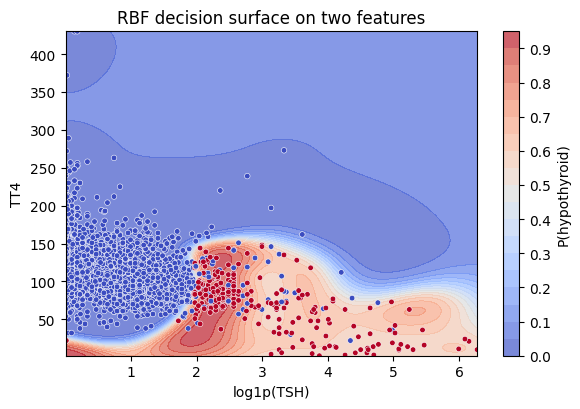

In [10]:
pair = ["TSH", "TT4"]
two = svm(C=10).fit(X_train[pair], y_train)

xx, yy = np.meshgrid(
    np.linspace(X_train[pair[0]].min(), X_train[pair[0]].max(), 200),
    np.linspace(np.nanmin(X_train[pair[1]]), np.nanmax(X_train[pair[1]]), 200),
)
grid_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=pair)
zz = two.predict_proba(grid_points)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 4.2))
cs = ax.contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.7)
ax.scatter(X_train[pair[0]], X_train[pair[1]], c=y_train, cmap="coolwarm",
           edgecolor="white", linewidth=0.4, s=16)
ax.set_xlabel("log1p(TSH)")
ax.set_ylabel("TT4")
ax.set_title("RBF decision surface on two features")
fig.colorbar(cs, ax=ax, label="P(hypothyroid)")
plt.tight_layout()
plt.show()